# EV Battery Health Prediction: Step 3b, Does the Target Definition Matter?

In Step 3 every model **under-predicted the SOH in early life** on the unseen battery B0018. The true SOH started at 100%, but the models predicted around 90 to 95%. Random Forest and XGBoost followed the shape of the curve well, so the problem was not the shape, it was the starting level.

In this notebook I test one idea for why that happens, and a fix for it.

| Step | What I do |
|---|---|
| 1 | Load the NASA data for one battery, calculate SOH, plot the capacity fade |
| 2 | Combine 4 batteries and explore the data |
| 3 | Train models to predict SOH |
| **3b (this notebook)** | **Compare two ways of defining what the model predicts** |
| 4 | Explain the model with SHAP |
| 5 | Predict Remaining Useful Life (RUL) |
| 6 | Build and deploy a Streamlit app |

## 1. The idea

I calculated SOH as:

`SOH (%) = capacity now / capacity at the battery's own first cycle x 100`

That means a battery always starts at exactly 100%, **whatever its real capacity is**. But the four batteries do not start at the same capacity. In the capacity plot from Step 2, B0006 started much higher than the others.

If two batteries behave the same electrically but start at different capacities, they get **different SOH labels** for the same measurements. The model cannot tell them apart from voltage, current and temperature alone, so it ends up guessing something in the middle.

**What I test:** instead of predicting SOH directly, predict the **capacity in Ah** (a real physical quantity), and then convert to SOH afterwards using the battery's starting capacity.

## 2. Importing libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

## 3. Loading the data and checking the starting capacities

First I checked whether the batteries really start at different capacities.

In [2]:
df = pd.read_csv("all_batteries.csv").sort_values(["battery", "cycle"]).reset_index(drop=True)

start_capacity = df.groupby("battery")["capacity_ah"].first().round(3)
last_capacity = df.groupby("battery")["capacity_ah"].last().round(3)

pd.DataFrame(
    {
        "capacity at cycle 1 (Ah)": start_capacity,
        "capacity at last cycle (Ah)": last_capacity,
        "cycles": df.groupby("battery").size(),
    }
)

,capacity at cycle 1 (Ah),capacity at last cycle (Ah),cycles
battery,,,
B0005,1.856,1.325,168
B0006,2.035,1.186,168
B0007,1.891,1.432,168
B0018,1.855,1.341,132


These cells are all rated at about 2.0 Ah, but the measured capacity at cycle 1 differs from battery to battery. With the "own first cycle = 100%" rule, that difference disappears from the labels: a battery that starts at 2.03 Ah and one that starts at 1.86 Ah both get 100%.

## 4. Two ways to predict

| | Approach A (what I did in Step 3) | Approach B (new) |
|---|---|---|
| Model target | SOH (%) | Capacity (Ah) |
| Converting to SOH | Not needed | `SOH = predicted capacity / starting capacity x 100` |
| Needs the starting capacity? | No | Yes, but only to convert at the end |

Both use the same features, the same XGBoost settings, and the same split as Step 3: train on **B0005, B0006, B0007**, test on **B0018**.

For approach B, the starting capacity of the test battery is its measured capacity at cycle 1. For a real battery this would be known from when it was new, or I could use the rated capacity.

In [3]:
FEATURES = [
    "avg_voltage",
    "min_voltage",
    "avg_current",
    "avg_temp",
    "max_temp",
    "discharge_time_s",
]

TRAIN_BATTERIES = ["B0005", "B0006", "B0007"]
TEST_BATTERY = "B0018"


def make_model():
    return XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=3, random_state=42)


train = df[df["battery"].isin(TRAIN_BATTERIES)]
test = df[df["battery"] == TEST_BATTERY]
test_start = test["capacity_ah"].iloc[0]

# Approach A: predict SOH directly
pred_soh_a = make_model().fit(train[FEATURES], train["soh_percent"]).predict(test[FEATURES])

# Approach B: predict capacity, then convert to SOH
pred_cap_b = make_model().fit(train[FEATURES], train["capacity_ah"]).predict(test[FEATURES])
pred_soh_b = pred_cap_b / test_start * 100

print(f"Test battery {TEST_BATTERY} starts at {test_start:.3f} Ah")

Test battery B0018 starts at 1.855 Ah


## 5. Results on the unseen battery

I report the errors in **SOH points** so both approaches can be compared directly. I also report the error in **Ah**, which does not depend on how SOH is defined, by converting approach A's SOH back to Ah.

The last column is the average error over the **first 20 cycles**, with the sign kept (prediction minus actual). A negative number means the model predicted too low, which is the early-life problem from Step 3.

In [4]:
actual_soh = test["soh_percent"].values
actual_cap = test["capacity_ah"].values

pred_cap_a = pred_soh_a / 100 * test_start  # approach A converted back to Ah


def summarise(name, pred_soh, pred_cap):
    return {
        "Approach": name,
        "MAE (SOH pts)": mean_absolute_error(actual_soh, pred_soh),
        "RMSE (SOH pts)": np.sqrt(mean_squared_error(actual_soh, pred_soh)),
        "R2": r2_score(actual_soh, pred_soh),
        "MAE (Ah)": mean_absolute_error(actual_cap, pred_cap),
        "Early-life bias (first 20 cycles, SOH pts)": float((pred_soh[:20] - actual_soh[:20]).mean()),
    }


results = pd.DataFrame(
    [
        summarise("A: predict SOH directly", pred_soh_a, pred_cap_a),
        summarise("B: predict capacity, then SOH", pred_soh_b, pred_cap_b),
    ]
).round(3)

results.to_csv("results_step3b.csv", index=False)
results

,Approach,MAE (SOH pts),RMSE (SOH pts),R2,MAE (Ah),"Early-life bias (first 20 cycles, SOH pts)"
0,A: predict SOH directly,1.882,2.319,0.922,0.035,-3.534
1,"B: predict capacity, then SOH",0.873,1.123,0.982,0.016,0.393


## 6. Predicted vs actual SOH

The black line is the real SOH of B0018. If approach B fixed the early-life problem, its line should sit on top of the black one from the first cycle.

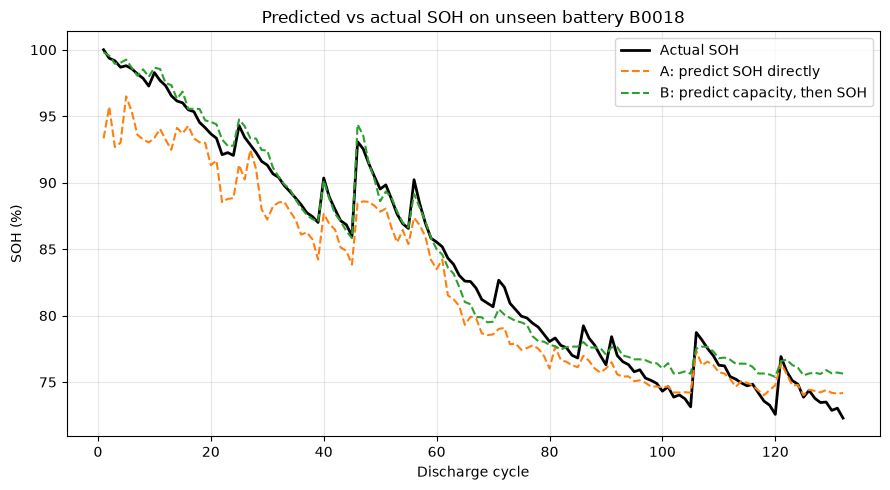

In [5]:
plt.figure(figsize=(9, 5))
plt.plot(test["cycle"], actual_soh, color="black", linewidth=2, label="Actual SOH")
plt.plot(test["cycle"], pred_soh_a, linestyle="--", color="tab:orange", label="A: predict SOH directly")
plt.plot(test["cycle"], pred_soh_b, linestyle="--", color="tab:green", label="B: predict capacity, then SOH")
plt.title(f"Predicted vs actual SOH on unseen battery {TEST_BATTERY}")
plt.xlabel("Discharge cycle")
plt.ylabel("SOH (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("step3b_comparison.png", dpi=150)
plt.show()

## 7. Is it just luck on one battery? Leave-one-battery-out

B0018 is a single test battery, so a good result there could be luck. To check, I repeated the comparison **four times**, each time holding out a different battery and training on the other three.

For every held-out battery, approach B uses that battery's own measured capacity at cycle 1 as the starting capacity.

In [6]:
rows = []
for hold in df["battery"].unique():
    tr = df[df["battery"] != hold]
    te = df[df["battery"] == hold]
    start = te["capacity_ah"].iloc[0]

    a = make_model().fit(tr[FEATURES], tr["soh_percent"]).predict(te[FEATURES])
    b = make_model().fit(tr[FEATURES], tr["capacity_ah"]).predict(te[FEATURES]) / start * 100

    rows.append(
        {
            "Held-out battery": hold,
            "Starts at (Ah)": round(start, 3),
            "A: MAE (SOH pts)": mean_absolute_error(te["soh_percent"], a),
            "B: MAE (SOH pts)": mean_absolute_error(te["soh_percent"], b),
        }
    )

lobo = pd.DataFrame(rows).round(2)
lobo.to_csv("results_step3b_leave_one_out.csv", index=False)
lobo

,Held-out battery,Starts at (Ah),A: MAE (SOH pts),B: MAE (SOH pts)
0,B0005,1.86,1.26,1.69
1,B0006,2.04,7.58,2.20
2,B0007,1.89,1.92,1.07
3,B0018,1.86,1.88,0.87


In [7]:
print("Average MAE over the four held-out batteries (SOH points):")
print(f"  A: predict SOH directly:        {lobo['A: MAE (SOH pts)'].mean():.2f}")
print(f"  B: predict capacity, then SOH:  {lobo['B: MAE (SOH pts)'].mean():.2f}")

Average MAE over the four held-out batteries (SOH points):
  A: predict SOH directly:        3.16
  B: predict capacity, then SOH:  1.46


## 8. What I found

*These numbers are from my run. If yours differ slightly after you re-run, trust the tables above.*

- **On B0018, predicting capacity roughly halved the error.** MAE went from about 1.88 to about 0.87 SOH points, and RMSE from about 2.32 to about 1.12.
- **The early-life under-prediction went away.** Approach A was about 3.5 points too low over the first 20 cycles, while approach B was within about half a point.
- **The leave-one-out check backs this up on average**, with the mean MAE falling from about 3.16 to about 1.46 SOH points.
- **The biggest gain was on B0006**, the battery with the highest starting capacity: MAE went from about 7.58 to about 2.20. That fits the idea, because B0006 is exactly the battery whose labels do not match the others when every battery is forced to start at 100%.
- **It did not win everywhere.** On B0005 approach A was slightly better (about 1.26 vs 1.69), so the improvement is large on average but not guaranteed for every battery.

So the way SOH is defined for the model matters. Predicting a physical quantity (capacity) and converting afterwards worked better than predicting a percentage whose baseline changes from battery to battery.

## 9. Limitations

- **Approach B needs the starting capacity.** It is known for a new battery (its first measurement, or the rated value of about 2.0 Ah), but not if only a few mid-life measurements are available. If the rated capacity is used instead of the true first-cycle capacity, the SOH shifts by the difference between them. For B0018 that is about 7 points, because it starts at 1.86 Ah and not 2.0 Ah.
- **Only four batteries.** Even with leave-one-out, this is a very small sample from one lab.
- **Discharge time is almost the same information as capacity.** Capacity is current multiplied by time, and inside each battery the correlation between discharge time and capacity is about 0.98 to 0.99. A good part of the model's accuracy may come from this. In a real EV, a full discharge down to the cutoff is rare, so a model that needs it is much less practical than it looks here.
- **Average current is a measured value, not a fixed setting.** It drifts slowly as the battery ages (in B0005 it goes from about -1.82 A to about -1.70 A), so it carries some health information too.
- **Lab data, not real driving.**

## 10. Next step

I will switch the Streamlit app to approach B, so the app predicts capacity and shows SOH relative to a starting capacity the user can enter (with 2.0 Ah as the default).